# 01 · Exploring the Electricity dataset

**Project:** reproduce LSTNet (Lai et al., SIGIR 2018) on Electricity, horizon 24, then test
whether a simple linear model or RevIN changes the picture.

**Questions for this notebook**
1. Is the file what the paper describes (26,304 hourly steps × 321 customers)?
2. Where are the 60/20/20 chronological split boundaries?
3. How different are the customers in scale? (This explains the per-series normalisation.)
4. Are there zeros, late starts or constant series that affect training or the CORR metric?
5. Are the daily (24 h) and weekly (168 h) patterns there, as in the paper's Figure 3c?
6. Does the level of a series change between training and test? The paper's argument for the
   AR component (Sec. 4.6) rests on this.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path("../data/electricity.txt.gz")      # created by scripts/download_data.sh
FIGS = Path("../results/figures")
FIGS.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 110
rng = np.random.default_rng(0)                  # fixed seed so the random series picks repeat

## 1 · Load and check the shape

One line per hour, one comma-separated column per customer (kWh).
The file has no timestamps; the paper says the data covers 2012–2014.

In [2]:
x = np.loadtxt(DATA, delimiter=",")
T, n = x.shape
print(f"shape: {x.shape}  (time steps × customers)")
assert x.shape == (26304, 321), "not the shape the paper reports"
print(f"missing values: {np.isnan(x).sum()}")
print(f"min {x.min():.0f}, max {x.max():.0f} kWh")
print(f"{T} hours = {T / 24:.0f} days = {T / 24 / 365:.2f} years")

shape: (26304, 321)  (time steps × customers)
missing values: 0
min 0, max 764000 kWh
26304 hours = 1096 days = 3.00 years


## 2 · Chronological split (60 / 20 / 20)

Same as the authors' code: the boundaries are at 60% and 80% of the time steps.
No shuffling across the boundaries, so the test set is truly "the future".

In [3]:
train_end = int(0.6 * T)
valid_end = int(0.8 * T)
print(f"train: steps 0 .. {train_end - 1}      ({train_end} steps, {train_end / 24:.0f} days)")
print(f"valid: steps {train_end} .. {valid_end - 1}  ({valid_end - train_end} steps, {(valid_end - train_end) / 24:.0f} days)")
print(f"test : steps {valid_end} .. {T - 1}  ({T - valid_end} steps, {(T - valid_end) / 24:.0f} days)")

# With window q = 168 and horizon h = 24, the first usable target is at step q + h - 1.
q, h = 168, 24
print(f"\ntraining targets start at step {q + h - 1}, so about {train_end - (q + h - 1)} training windows")

train: steps 0 .. 15781      (15782 steps, 658 days)
valid: steps 15782 .. 21042  (5261 steps, 219 days)
test : steps 21043 .. 26303  (5261 steps, 219 days)

training targets start at step 191, so about 15591 training windows


## 3 · How different are the customers in scale?

If one customer uses 100× more than another, a model trained on raw kWh would care almost only
about the big customers. That is why the authors divide every series by its own maximum.

per-customer mean load: smallest 10.6, median 592.0, largest 200529.1 kWh
ratio largest / smallest mean: 18869×


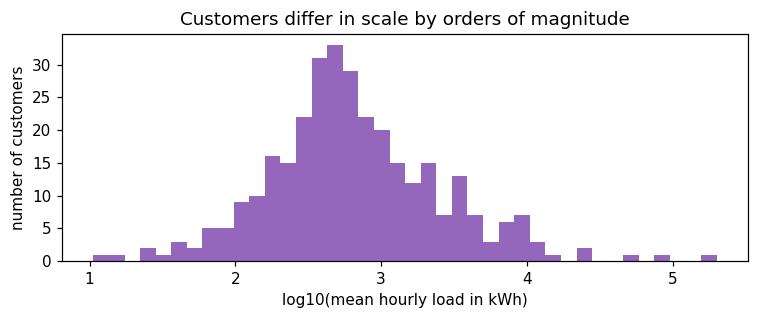

In [4]:
series_max = x.max(axis=0)
series_mean = x.mean(axis=0)
print(f"per-customer mean load: smallest {series_mean.min():.1f}, median {np.median(series_mean):.1f}, largest {series_mean.max():.1f} kWh")
print(f"ratio largest / smallest mean: {series_mean.max() / series_mean.min():.0f}×")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(np.log10(series_mean), bins=40, color="tab:purple")
ax.set_xlabel("log10(mean hourly load in kWh)")
ax.set_ylabel("number of customers")
ax.set_title("Customers differ in scale by orders of magnitude")
plt.tight_layout()
plt.show()

## 4 · A few customers over the whole period

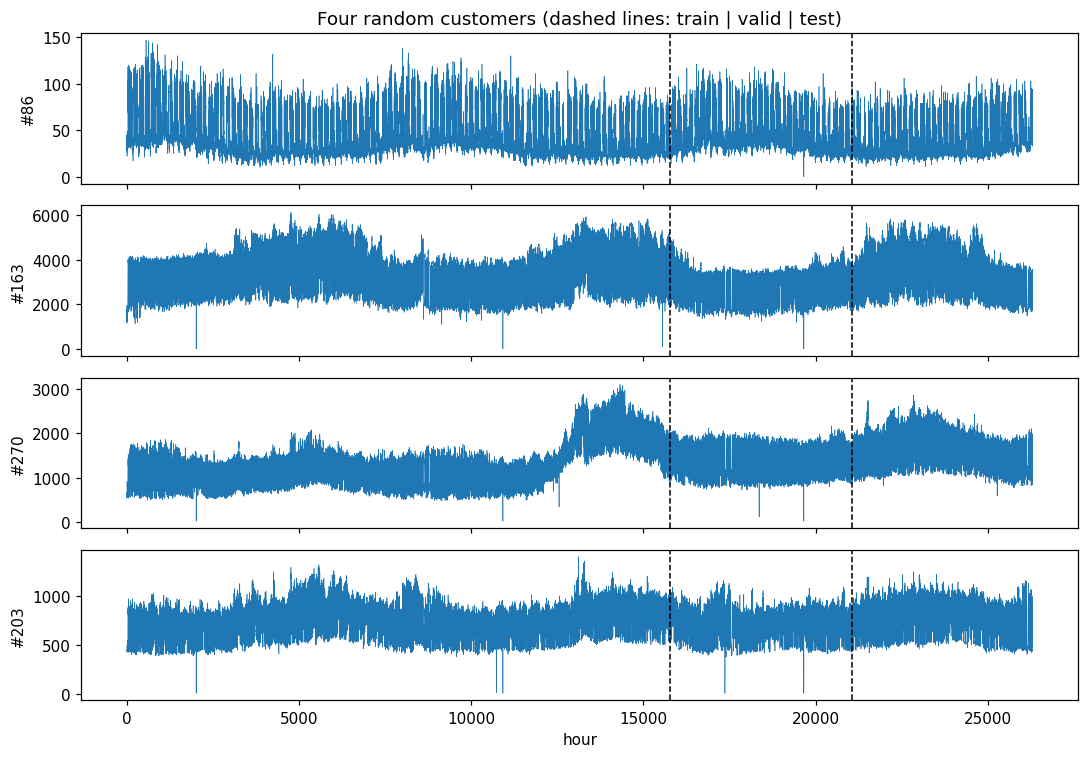

In [5]:
picks = rng.choice(n, size=4, replace=False)
fig, axes = plt.subplots(4, 1, figsize=(10, 7), sharex=True)
for ax, j in zip(axes, picks):
    ax.plot(x[:, j], lw=0.4, color="tab:blue")
    ax.axvline(train_end, color="k", ls="--", lw=1)
    ax.axvline(valid_end, color="k", ls="--", lw=1)
    ax.set_ylabel(f"#{j}")
axes[0].set_title("Four random customers (dashed lines: train | valid | test)")
axes[-1].set_xlabel("hour")
plt.tight_layout()
plt.show()

## 5 · Zeros, late starts and constant series

* **Zeros:** some customers report 0 kWh at the start, as if they joined later.
* **Constant in test:** a series with zero variance in the test targets has no defined
  correlation. The authors' code drops such series from the CORR average; we must do the same
  and report how many.

In [6]:
zero_frac = (x == 0).mean(axis=0)
print(f"share of all values that are 0: {(x == 0).mean():.2%}")
print(f"customers with any zeros: {(zero_frac > 0).sum()} of {n}")
print(f"customers with more than 10% zeros: {(zero_frac > 0.10).sum()}")

# Late starts: length of the run of zeros at the very beginning of each series
first_nonzero = np.argmax(x != 0, axis=0)
late = first_nonzero > 0
print(f"customers whose series starts with zeros: {late.sum()}; longest leading run {first_nonzero.max()} h ({first_nonzero.max() / 24:.0f} days)")

test = x[valid_end:]
const_test = np.where(test.std(axis=0) == 0)[0]
print(f"customers constant over the whole test period: {len(const_test)} -> ids {const_test.tolist()}")
for j in const_test:
    print(f"  #{j}: test value {test[0, j]}, train mean {x[:train_end, j].mean():.1f}")

share of all values that are 0: 1.09%
customers with any zeros: 229 of 321
customers with more than 10% zeros: 6
customers whose series starts with zeros: 1; longest leading run 160 h (7 days)
customers constant over the whole test period: 1 -> ids [182]
  #182: test value 0.0, train mean 1203.3


## 6 · Daily and weekly patterns (compare with Figure 3c of the paper)

Autocorrelation at lag τ = correlation of the series with itself shifted by τ hours.
Peaks at 24 h mean "same hour yesterday looks like now"; peaks at 168 h mean "same hour last
week". This is the reason for the skip length **p = 24** in LSTNet-Skip.

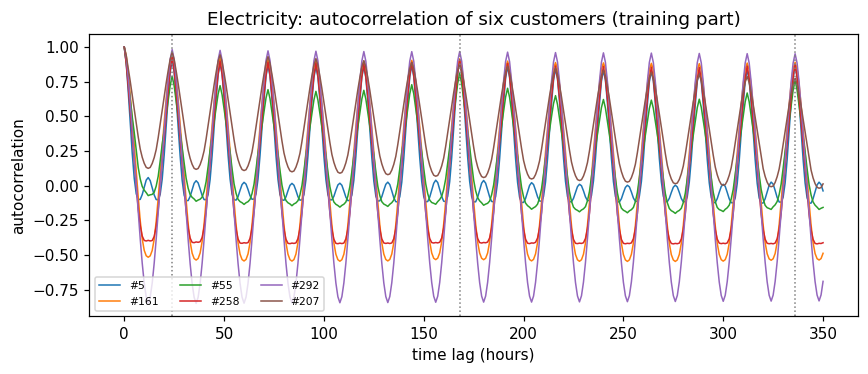

In [7]:
def autocorr(series, max_lag):
    """Autocorrelation for the lags 0, 1, ..., max_lag."""
    s = series - series.mean()              # centre the series around 0
    var = (s * s).sum()
    result = []
    for k in range(max_lag + 1):
        # multiply the series with itself shifted by k steps, add up, scale to -1 .. 1
        result.append((s[: len(s) - k] * s[k:]).sum() / var)
    return np.array(result)

max_lag = 350   # same range as the paper's plot
fig, ax = plt.subplots(figsize=(8, 3.5))
for j in rng.choice(n, size=6, replace=False):
    ax.plot(autocorr(x[:train_end, j], max_lag), lw=1, label=f"#{j}")
for lag in (24, 168, 336):
    ax.axvline(lag, color="grey", ls=":", lw=1)
ax.set_xlabel("time lag (hours)")
ax.set_ylabel("autocorrelation")
ax.set_title("Electricity: autocorrelation of six customers (training part)")
ax.legend(fontsize=7, ncol=3)
plt.tight_layout()
fig.savefig(FIGS / "electricity_autocorrelation.png")
plt.show()

In [8]:
# How strong are the two patterns across ALL customers?
acf_all = np.array([autocorr(x[:train_end, j], 168) for j in range(n)])
print(f"median autocorrelation at lag  24 h: {np.median(acf_all[:, 24]):.2f}")
print(f"median autocorrelation at lag 168 h: {np.median(acf_all[:, 168]):.2f}")
print(f"median autocorrelation at lag  12 h: {np.median(acf_all[:, 12]):.2f}  (half a day, for contrast)")

median autocorrelation at lag  24 h: 0.94
median autocorrelation at lag 168 h: 0.91
median autocorrelation at lag  12 h: -0.38  (half a day, for contrast)


## 7 · Does the level change between training and test?

The paper says the neural part cannot follow changes in scale, so the linear AR part is needed
(Sec. 4.6, Fig. 6). If many customers use clearly more or less in the test period than in
training, that is a **distribution shift**, which is exactly what RevIN is designed for.

test mean / train mean per customer: median 0.99
customers whose level changes by more than 20%: 24 of 321
customers whose level changes by more than 50%: 8 of 321
customers that drop to zero in the test period: 1


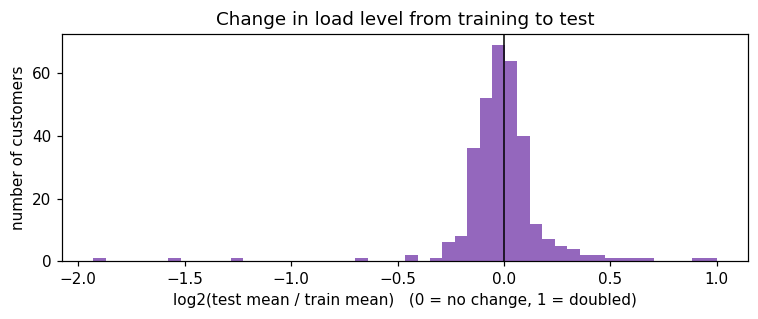

In [9]:
train_mean = x[:train_end].mean(axis=0)
test_mean = x[valid_end:].mean(axis=0)
ok = train_mean > 0
ratio = test_mean[ok] / train_mean[ok]

print(f"test mean / train mean per customer: median {np.median(ratio):.2f}")
print(f"customers whose level changes by more than 20%: {((ratio < 0.8) | (ratio > 1.2)).sum()} of {ok.sum()}")
print(f"customers whose level changes by more than 50%: {((ratio < 0.5) | (ratio > 1.5)).sum()} of {ok.sum()}")

print(f"customers that drop to zero in the test period: {(ratio == 0).sum()}")

# log2 of 0 is -inf, so the histogram only shows customers that still use electricity in test
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(np.log2(ratio[ratio > 0]), bins=50, color="tab:purple")
ax.axvline(0, color="k", lw=1)
ax.set_xlabel("log2(test mean / train mean)   (0 = no change, 1 = doubled)")
ax.set_ylabel("number of customers")
ax.set_title("Change in load level from training to test")
plt.tight_layout()
fig.savefig(FIGS / "electricity_level_shift.png")
plt.show()

## 8 · Normalisation as in the authors' code

`normalize=2`: divide each series by its maximum absolute value. The maximum is taken over the
**whole** series, test period included. That uses a tiny bit of information from the future;
we keep it so our numbers are comparable with the paper, and note it in the report.
How often does that matter, i.e. how often is a customer's maximum in the test period?

In [10]:
scale = np.abs(x).max(axis=0)
scale[scale == 0] = 1                       # guard against division by zero
x_norm = x / scale
print(f"after scaling: min {x_norm.min():.2f}, max {x_norm.max():.2f}")

where_max = np.argmax(x, axis=0)
in_test = (where_max >= valid_end).sum()
print(f"customers whose overall maximum lies in the test period: {in_test} of {n}")

train_scale = np.abs(x[:train_end]).max(axis=0)
print(f"median (whole-series max / train-only max): {np.median(scale / np.maximum(train_scale, 1e-9)):.2f}")

after scaling: min 0.00, max 1.00
customers whose overall maximum lies in the test period: 53 of 321
median (whole-series max / train-only max): 1.00


## 9 · Summary

| Question | Finding | Consequence for the project |
|---|---|---|
| Shape | 26,304 h × 321 customers, no missing values: matches the paper | Use the file as is |
| Split | train 15,782 h (658 days), valid and test 5,261 h (219 days) each | About 15,600 training windows for q = 168, h = 24 |
| Scale | Mean load ranges from about 11 to 200,000 kWh (a factor of ~19,000) | Per-series normalisation is essential |
| Zeros | 1.1% of values; one customer starts with a week of zeros; customer #182 is 0 for the whole test period | #182 is dropped from CORR (zero variance), as in the authors' code; report it |
| Patterns | Median autocorrelation 0.94 at 24 h and 0.91 at 168 h, −0.38 at 12 h | Strong daily and weekly cycles: supports skip length p = 24 and window q = 168 |
| Level shift | Median test/train level ratio 0.99; 24 customers change by >20%, 8 by >50% | Shift is modest for most customers but large for a few. RevIN normalises each input window, so it also handles local level changes, not only this train-vs-test shift. Expect a modest gain at best and say so |
| Normalisation | 53 customers have their overall maximum in the test period, but the median ratio of whole-series max to train-only max is 1.00 | The leakage from the authors' scaling is small; keep it for comparability and mention it in the report |